# 78. Subsets
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Subsets](README.md) · **LeetCode:** https://leetcode.com/problems/subsets/

## 💡 Concepts

**Core concept(s):** **backtracking with an include / exclude decision** at every index.

**Why it applies here:**
- A subset is fully described by `n` yes/no answers: is `nums[0]` in it? is `nums[1]` in it? ...
- `n` binary decisions give `2 × 2 × ... × 2 = 2ⁿ` subsets, and a recursion that branches twice per index visits each of them exactly once.
- The answer *is* the whole list of `2ⁿ` subsets, so no algorithm can beat `O(n·2ⁿ)`: just writing the output costs that much.

**Key intuition:**
- Walk the array left to right with one shared `path`.
- At index `i`, first explore *with* `nums[i]` (append, recurse, pop), then explore *without* it (recurse).
- When `i == n`, every element has been decided: `path` is one finished subset, so record a copy.

---

### 📚 What is a Power Set?
- The **power set** of a collection is the set of **all** its subsets, including the empty set `[]` and the collection itself.
- A set of `n` distinct elements has exactly **2ⁿ** subsets: each element is either in or out.
- Example: `[1, 2]` → `[[], [1], [2], [1, 2]]`, which is `2² = 4` subsets.
- The total size of the output is about `n·2ⁿ / 2` numbers (each element is in half the subsets).

### 📚 What is a Bitmask?
- A **bitmask** is an integer whose binary digits are used as on/off switches.
- With `n` elements, the integers `0 .. 2ⁿ − 1` are exactly all `n`-bit patterns, so each one can stand for one subset: bit `i` set means "`nums[i]` is in".
- Testing bit `i` is `mask >> i & 1`, **O(1)**. Reading a whole subset out of a mask is **O(n)**.
- **In Python:** plain `int` with `1 << n`, `>>`, `&`.

### 📚 What is Recursion?
- A **recursive** function solves a problem by calling itself on a smaller piece of the same problem.
- Every call gets its own frame on the **call stack**; when a call returns, Python resumes the caller exactly where it left off.
- A **base case** stops the calls (here: "every element has been decided").
- **Cost:** the stack holds one frame per level of depth, so a recursion `n` levels deep uses **O(n)** stack space.
- **In Python:** a nested `def backtrack(i): ...` that can read the outer `nums`, `path`, `out`. The default recursion limit (~1000) is far above `n <= 10`.

### 📚 What is Backtracking?
- **Backtracking** builds a candidate answer one decision at a time and **undoes** each decision after exploring it, so the same working list can be reused for every branch.
- The template is three moves: **choose** (`path.append(x)`), **explore** (recurse), **un-choose** (`path.pop()`).
- The decisions form a **recursion tree**: each node is a partial answer, each edge a decision.
- When a node is a complete answer, store a **copy**: `out.append(path[:])`. Storing `path` itself stores a reference to a list that keeps changing.
- **Cost:** proportional to the number of tree nodes times the work per node (often the `O(n)` copy).
- **In Python:** one shared `list` as `path`; `append` / `pop` at the end are both O(1).

### 📚 What is the include / exclude decision tree?
- For subsets, the decision at index `i` is binary: **include** `nums[i]` in the subset, or **exclude** it.
- After `n` binary decisions every element is decided, so the tree has exactly **2ⁿ leaves**, one per subset.
- Leaves are the only place anything is recorded (`if i == len(nums)`).
- The tree has `2ⁿ⁺¹ − 1` calls in total: the internal decision nodes plus the leaves.

### 📚 What is the start-index loop?
- The other common backtracking shape: `backtrack(start)` loops `for i in range(start, n)` and recurses with `i + 1`.
- Only moving **forward** means `[1, 2]` can be built but `[2, 1]` cannot, so no subset appears twice.
- For subsets, **every** node is an answer, so it records on entry, before the loop.
- It makes exactly one call per subset: `2ⁿ` calls.

---

**Prerequisite knowledge:**
- Recursive DFS (see [Deep Dive 21 — Backtracking](../../../deep_dive/21_Backtracking/README.md), which teaches the same `subsets` and `subsets_start_index` functions).
- Python list copying: `path[:]` makes a new list; `path` alone is a reference.

## 📝 Problem

Given an integer array `nums` of **unique** elements, return **all possible subsets** (the power set). The answer must not contain duplicate subsets. Return them in any order.

**Example 1**
```
nums = [1, 2, 3]  ->  [[], [1], [2], [1, 2], [3], [1, 3], [2, 3], [1, 2, 3]]   (2³ = 8 subsets)
```

**Example 2**
```
nums = [0]  ->  [[], [0]]
```

**Constraints:** `1 <= nums.length <= 10`, `-10 <= nums[i] <= 10`, all numbers in `nums` are unique.

> Three approaches, all `O(n·2ⁿ)` because the output itself has `2ⁿ` lists: a bitmask brute force, the include/exclude backtracking template, and the start-index loop that builds the same subsets in a different order.

In [1]:
from typing import List
from itertools import combinations


def canon(subsets: List[List[int]]) -> List[List[int]]:
    """Order-free form for comparing answers: sort inside each subset, then sort the list of subsets."""
    return sorted(sorted(s) for s in subsets)


def reference_subsets(nums: List[int]) -> List[List[int]]:
    """Independent ground truth for the tests: every combination of every size, from itertools."""
    return [list(c) for k in range(len(nums) + 1) for c in combinations(nums, k)]

### Approach 1 — Brute Force: bitmask enumeration

**Idea:**
1. There are `2ⁿ` subsets, and the integers `0 .. 2ⁿ − 1` are exactly the `2ⁿ` patterns of `n` bits.
2. For each integer `mask`, build the subset that contains `nums[i]` whenever bit `i` of `mask` is set.
3. Each mask is a different bit pattern, so each subset is produced exactly once.

**Time complexity:** `O(n·2ⁿ)` — `2ⁿ` masks, and each one tests all `n` bits.

**Space complexity:** `O(n)` extra for the subset being built (the `O(n·2ⁿ)` output aside).

In [2]:
def subsets_bitmask(nums: List[int]) -> List[List[int]]:
    n = len(nums)
    out = []
    for mask in range(1 << n):                 # 0 .. 2^n - 1: one integer per subset
        subset = []
        for i in range(n):
            if mask >> i & 1:                  # bit i is on -> nums[i] is in this subset
                subset.append(nums[i])
        out.append(subset)
    return out

### Approach 2 — Backtracking: include / exclude (optimal · pattern template)

**Idea:** the [Subsets](README.md) template. `backtrack(i)` decides `nums[i]`.
1. **Base case:** `i == len(nums)` — every element is decided, so `path` is a finished subset. Record a **copy**.
2. **Include:** `path.append(nums[i])`, recurse into `i + 1`, then `path.pop()` (un-choose) so the next branch starts clean.
3. **Exclude:** recurse into `i + 1` again, this time without `nums[i]`.

The recursion tree has exactly `2ⁿ` leaves, one per subset, and every leaf is at depth `n`.

**Time complexity:** `O(n·2ⁿ)` — `2ⁿ⁺¹ − 1` calls, each `O(1)` except the `2ⁿ` leaves, which copy a path of up to `n` numbers.

**Space complexity:** `O(n)` — recursion depth `n` plus the shared `path` (output aside).

> Same `O(n·2ⁿ)` time as Approach 1, and no approach can do better because the output has `2ⁿ` lists. This is the interview target because the same template (choose, explore, un-choose) solves Subsets II, Combinations and Combination Sum with one or two lines changed.

In [3]:
def subsets_include_exclude(nums: List[int]) -> List[List[int]]:
    out, path = [], []

    def backtrack(i: int) -> None:
        if i == len(nums):                     # base case: every element decided
            out.append(path[:])                # record a COPY; `path` keeps changing
            return
        path.append(nums[i])                   # INCLUDE nums[i]
        backtrack(i + 1)
        path.pop()                             # UN-CHOOSE: undo before the other branch

        backtrack(i + 1)                       # EXCLUDE nums[i]

    backtrack(0)
    return out

### Approach 3 — Backtracking: start-index loop (alternate shape)

**Idea:** the same subsets, built by choosing *which element comes next* instead of yes/no per element.
1. `backtrack(start)` first records `path` — every node of this tree is a valid subset, not just the leaves.
2. Then it loops `i` from `start` to `n − 1`: **choose** `nums[i]`, **explore** `backtrack(i + 1)`, **un-choose**.
3. Recursing with `i + 1` means the next pick always comes from further right, so `[1, 2]` is built but `[2, 1]` never is.

**Time complexity:** `O(n·2ⁿ)` — exactly one call per subset (`2ⁿ` calls), each copying up to `n` numbers.

**Space complexity:** `O(n)` — recursion depth at most `n` plus `path` (output aside).

> Same subsets as Approach 2, in a different order (the empty set comes first). This loop shape is the one Subsets II's `if i > start and nums[i] == nums[i - 1]: continue` skip is written for.

In [4]:
def subsets_start_index(nums: List[int]) -> List[List[int]]:
    out, path = [], []

    def backtrack(start: int) -> None:
        out.append(path[:])                    # record on ENTRY: every node is a subset
        for i in range(start, len(nums)):
            path.append(nums[i])               # CHOOSE nums[i] as the next element
            backtrack(i + 1)                   # EXPLORE: only indices after i
            path.pop()                         # UN-CHOOSE

    backtrack(0)
    return out

In [5]:
# Correctness check
import random

tests = [
    [1, 2, 3],          # LeetCode example 1
    [0],                # LeetCode example 2
    [],                 # empty input: only the empty subset
    [5, -3],            # negatives are just values
    [4, 1, 9, 7],       # unsorted input
]
for nums in tests:
    a, b, c = subsets_bitmask(nums), subsets_include_exclude(nums), subsets_start_index(nums)
    exp = canon(reference_subsets(nums))
    print(f"{str(nums):14} -> {len(c):2} subsets, start-index order: {c}")
    assert canon(a) == canon(b) == canon(c) == exp, f"mismatch on {nums}"
    assert len(a) == len(b) == len(c) == 2 ** len(nums)

print("\ninclude/exclude order on [1, 2, 3]:", subsets_include_exclude([1, 2, 3]))

# Randomised cross-check against itertools on distinct-value inputs
rng = random.Random(78)
for _ in range(300):
    nums = rng.sample(range(-10, 11), rng.randint(0, 10))
    exp = canon(reference_subsets(nums))
    for fn in (subsets_bitmask, subsets_include_exclude, subsets_start_index):
        got = fn(nums)
        assert canon(got) == exp, (fn.__name__, nums)
        assert len({tuple(sorted(s)) for s in got}) == len(got)   # no subset twice
print("300 random inputs: all three approaches match itertools")

print("\nAll tests passed")

[1, 2, 3]      ->  8 subsets, start-index order: [[], [1], [1, 2], [1, 2, 3], [1, 3], [2], [2, 3], [3]]
[0]            ->  2 subsets, start-index order: [[], [0]]
[]             ->  1 subsets, start-index order: [[]]
[5, -3]        ->  4 subsets, start-index order: [[], [5], [5, -3], [-3]]
[4, 1, 9, 7]   -> 16 subsets, start-index order: [[], [4], [4, 1], [4, 1, 9], [4, 1, 9, 7], [4, 1, 7], [4, 9], [4, 9, 7], [4, 7], [1], [1, 9], [1, 9, 7], [1, 7], [9], [9, 7], [7]]

include/exclude order on [1, 2, 3]: [[1, 2, 3], [1, 2], [1, 3], [1], [2, 3], [2], [3], []]
300 random inputs: all three approaches match itertools

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. Usually we double `n` and read the ratio. Here that is useless: the output has `2ⁿ` subsets, so doubling `n` from 10 to 20 would multiply the work by about 1000.

Instead the sizes grow by **one element at a time** (`n = 10, 11, ..., 16`). Each extra element doubles the number of subsets, so the expected ratio between consecutive rows is:

| Theoretical | Ratio when `n` → `n + 1` |
|-------------|--------------------------|
| `O(n²)`       | ≈ **1.1–1.2×** (barely moves) |
| `O(2ⁿ)`       | ≈ **2×** |
| `O(n·2ⁿ)`     | ≈ **2× · (n+1)/n ≈ 2.1×** |

The helper's footer line talks about ratios *per doubling*; for this table read every row as "per +1 element".

All three approaches are `O(n·2ⁿ)` on every input of distinct numbers, so there is no slower approach to separate here: the check is that all three grow ≈2× per element. The worst case is simply `n` distinct values. The log-log plot's `O(n)` / `O(n²)` reference lines are for polynomial growth; an exponential curve shoots far above them.


bitmask O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.46 |           n/a
       11 |       1.06 |         2.29x
       12 |       2.20 |         2.09x
       13 |       4.88 |         2.21x


       14 |      10.58 |         2.17x
       15 |      22.46 |         2.12x


       16 |      57.66 |         2.57x

include/exclude O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.20 |           n/a
       11 |       0.37 |         1.91x
       12 |       0.73 |         1.95x
       13 |       1.76 |         2.43x
       14 |       3.69 |         2.09x
       15 |       7.53 |         2.04x
       16 |      14.79 |         1.96x

start-index O(n*2^n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.18 |           n/a
       11 |       0.35 |         1.97x
       12 |       0.70 |         2.00x
       13 |       1.63 |         2.35x
       14 |       3.38 |         2.07x


       15 |       6.72 |         1.99x
       16 |      13.45 |         2.00x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


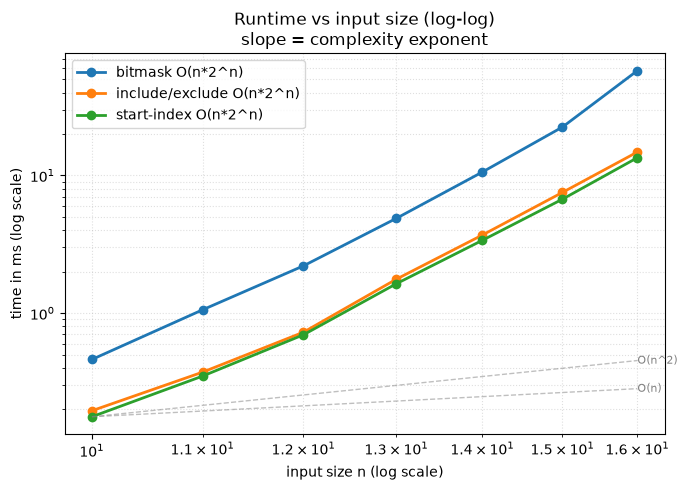

{'bitmask O(n*2^n)': [0.4603749839589,
  1.0557910427451134,
  2.203832962550223,
  4.8782090889289975,
  10.58354100678116,
  22.456458071246743,
  57.66345898155123],
 'include/exclude O(n*2^n)': [0.19529100973159075,
  0.37224998231977224,
  0.7266250904649496,
  1.7637499840930104,
  3.691165940836072,
  7.526625064201653,
  14.789082924835384],
 'start-index O(n*2^n)': [0.17666688654571772,
  0.34849997609853745,
  0.6960000609979033,
  1.6347500495612621,
  3.378459019586444,
  6.7215419840067625,
  13.449333957396448]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (list(range(n)),)          # n distinct values: all 2^n subsets must be produced

solutions = {
    "bitmask O(n*2^n)": subsets_bitmask,
    "include/exclude O(n*2^n)": subsets_include_exclude,
    "start-index O(n*2^n)": subsets_start_index,
}
sizes = list(range(10, 17))           # +1 element per row (not doubling): expect ~2x per row

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Subsets](README.md) — the include/exclude template as is: at every index, recurse once with `nums[i]` in `path` and once without it, and record a copy of `path` at the leaves (`i == n`).
- **Choose → explore → un-choose:** `path.append(x)`, recurse, `path.pop()`. The pop is what lets one shared list serve all `2ⁿ` branches.
- **Two shapes, same answer:** include/exclude records only at the `2ⁿ` leaves; the start-index loop records at every one of its `2ⁿ` nodes. Both cost `O(n·2ⁿ)`, which is the size of the output, so neither can be beaten.
- **Bitmask view:** the subsets of `n` items are the integers `0 .. 2ⁿ − 1`. Handy for small `n`, and the same counting argument explains why the output is `2ⁿ`.
- **Signal:** "all subsets", "power set", "every combination of any size", "each element is either picked or not".
- **Related problems:** Subsets II (duplicates, [subsets_ii.ipynb](subsets_ii.ipynb)), Combinations (LC 77: subsets of exactly size `k`), Combination Sum (LC 39), Letter Case Permutation (LC 784: a binary choice per letter).
- **Common pitfalls:**
  1. `out.append(path)` instead of `out.append(path[:])` — every entry is the same list, which is empty at the end.
  2. Forgetting `path.pop()` after the include branch — the "exclude" branch still contains `nums[i]`.
  3. Recursing with `start` or `0` instead of `i + 1` in the start-index loop — produces `[2, 1]` alongside `[1, 2]`, or never ends.
  4. Benchmarking by doubling `n` — `2²⁰` subsets is a million lists; grow `n` by one instead.